In [10]:
from utils.demo_utils import *

## Beispiel-Bild
- Regensburg DEZ-Kreuzung
- von Mapillary
- selbst annotiert

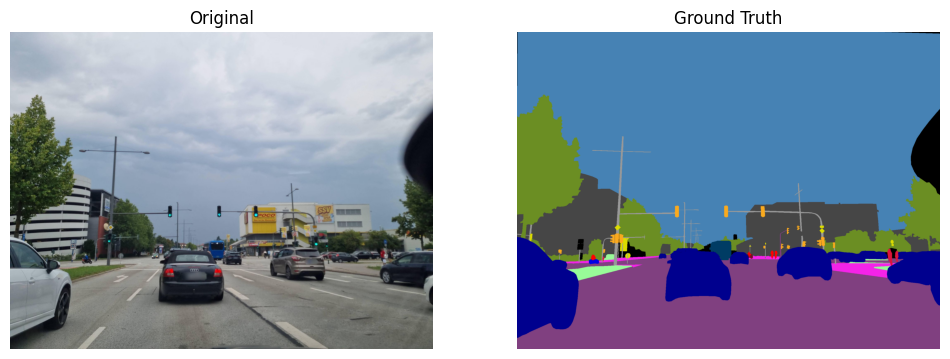

In [14]:
cvat_path = Path("./CVATAnnotations")
image_path = cvat_path / "bild1r.jpg"
label_path = cvat_path / "bild1.png"

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

rgb_label = cv2.imread(str(label_path))
rgb_label = cv2.cvtColor(rgb_label, cv2.COLOR_BGR2RGB)

plot_images(image, "Original", rgb_label, "Ground Truth")

## Segmentierung

Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 199
 - Train Loss: 0.06996467659870784
 - Train Accuracy: 0.9596164226531982
 - Train MIoU: 0.6942357507803419
 - Val Loss: 0.15436224887768427
 - Val Accuracy: 0.9292846322059631
 - Val MIoU: 0.5089366528013779


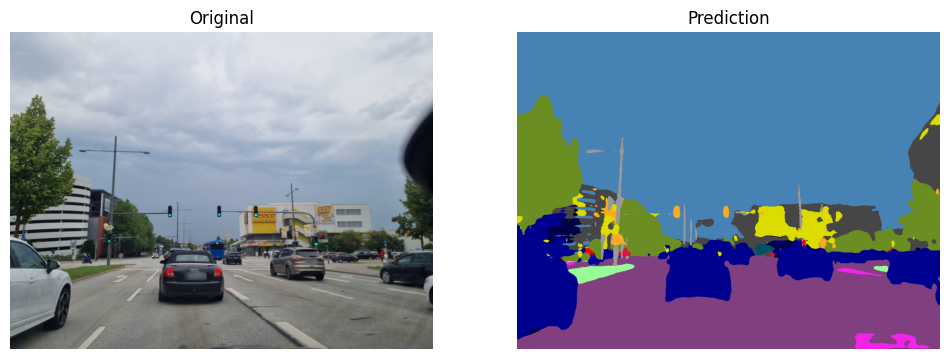

Results:
 - MIoU: 0.31546467327649297
 - Pixel Accuracy: 0.9140325784683228


In [16]:
model, device = load_model("deeplab", "deeplab_cityscapes_3258105")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

In [ ]:
#TODO Kennzahlen extrahieren und printen